# Can a model learn the radar's errors? A RainForest-style proof of concept

**Idea** (Wolfensberger et al. 2021, AMT, doi:10.5194/amt-14-3169-2021): train a random forest to predict gauge rain
from features of the radar around the gauge. Here: the radar-wow hourly total and its spread in a 5 x 5 km window,
beam height, blockage, distance and band, from five cases on four radars in three climates.

**The honest test** is a new event on a radar the model has not seen: train on four cases, predict the fifth
("leave one case out"). A random split of gauge-hours mixes neighbouring, strongly correlated samples of the same
event into training and test and flatters the model; it is shown only for contrast.

**Baselines.** Radar only, and radar times one factor learned from the training cases (the simplest correction).
A model is only useful if it beats that factor.

In [1]:
# Colab: uncomment to install
!pip install -q scikit-learn pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-ml"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.ml import RainForestQPE, gauge_samples, leave_one_case_out
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_fmi, fetch_hads, fetch_ideam

CACHE = os.path.expanduser("~/.cache/radarwow")
FIG = "../docs/figures"
CASES = {
    "KTLX 2022-05-05 (Oklahoma, S)": dict(site="KTLX", src="nexrad", s="2022-05-05 07:00", e="2022-05-05 11:00", nt=1, bb=False, g=("hads", "OK_DCP")),
    "KDAX 2021-10-24 (California, S)": dict(site="KDAX", src="nexrad", s="2021-10-24 12:00", e="2021-10-24 16:00", nt=3, bb=True, g=("hads", "CA_DCP")),
    "fianj 2023-08-30 (Finland, C)": dict(site="fianj", src="fmi", s="2023-08-30 12:00", e="2023-08-30 16:00", nt=3, bb=True, g=("fmi", None)),
    "fianj 2023-07-28 (Finland, C)": dict(site="fianj", src="fmi", s="2023-07-28 08:00", e="2023-07-28 12:00", nt=3, bb=True, g=("fmi", None)),
    "Tablazo 2023-08-20 (Colombia, C)": dict(site="Tablazo", src="ideam", s="2023-08-20 00:00", e="2023-08-20 12:00", nt=3, bb=True, g=("ideam", None)),
}

## 1. Samples: one per gauge-hour

In [3]:
frames = []
for name, c in CASES.items():
    rad = hourly_totals(c["site"], c["s"], c["e"], n_tilts=c["nt"], blockage=c["bb"], source=c["src"])
    la, lo = rad.attrs["radar_lat"], rad.attrs["radar_lon"]
    kind, net = c["g"]
    if kind == "hads":
        g = fetch_hads(net, la, lo, 145, c["s"], c["e"], f"{CACHE}/gauges")
    elif kind == "fmi":
        g = fetch_fmi(la, lo, 145, c["s"], c["e"], f"{CACHE}/gauges")
    else:
        g = fetch_ideam(la, lo, 145, c["s"], c["e"], f"{CACHE}/gauges", utc_offset_h=5)
    s = gauge_samples(rad, g, name)
    s = basic_qc(s.rename(columns={"radar_mm": "radar"}), radar_col="radar").rename(columns={"radar": "radar_mm"})
    frames.append(s[s.qc == "ok"].drop(columns="qc"))
df = pd.concat(frames, ignore_index=True)
display(Markdown("**Gauge-hours per case** (basic gauge QC)\n\n" + df.groupby("case").agg(gauge_hours=("gauge_mm", "size"), gauges=("station", "nunique"),
                 radar_over_gauge=("radar_mm", "sum")).assign(radar_over_gauge=lambda d: d.radar_over_gauge / df.groupby("case").gauge_mm.sum()).round(2).to_markdown()))

**Gauge-hours per case** (basic gauge QC)

| case                             |   gauge_hours |   gauges |   radar_over_gauge |
|:---------------------------------|--------------:|---------:|-------------------:|
| KDAX 2021-10-24 (California, S)  |           789 |      206 |               0.51 |
| KTLX 2022-05-05 (Oklahoma, S)    |           303 |       88 |               1.08 |
| Tablazo 2023-08-20 (Colombia, C) |           191 |       17 |               0.61 |
| fianj 2023-07-28 (Finland, C)    |            56 |       15 |               0.76 |
| fianj 2023-08-30 (Finland, C)    |            84 |       21 |               0.43 |

## 2. Leave one case out

In [4]:
out = leave_one_case_out(df)


def score(e, g):
    return dict(bias=e.sum() / g.sum(), MAE=np.mean(np.abs(e - g)), corr=np.corrcoef(e, g)[0, 1])


rows = []
for case, d in out.groupby("case", sort=False):
    for est in ["radar_mm", "scaled", "forest"]:
        rows.append(dict(case=case, estimate={"radar_mm": "radar only", "scaled": "radar x factor from other cases", "forest": "random forest"}[est],
                         **score(d[est].values, d.gauge_mm.values)))
res = pd.DataFrame(rows)
tab = res.pivot_table(index="case", columns="estimate", values="MAE").round(2)
display(Markdown("**Error (MAE, mm) when each case is predicted by a model trained on the other four**\n\n" + tab.to_markdown()))
tab2 = res.pivot_table(index="case", columns="estimate", values="bias").round(2)
display(Markdown("**Bias** (estimate / gauge)\n\n" + tab2.to_markdown()))

**Error (MAE, mm) when each case is predicted by a model trained on the other four**

| case                             |   radar only |   radar x factor from other cases |   random forest |
|:---------------------------------|-------------:|----------------------------------:|----------------:|
| KDAX 2021-10-24 (California, S)  |         4.1  |                              3.94 |            4.29 |
| KTLX 2022-05-05 (Oklahoma, S)    |         1.05 |                              2.55 |            2.3  |
| Tablazo 2023-08-20 (Colombia, C) |         0.72 |                              0.87 |            0.77 |
| fianj 2023-07-28 (Finland, C)    |         0.34 |                              0.47 |            0.5  |
| fianj 2023-08-30 (Finland, C)    |         0.96 |                              0.61 |            1    |

**Bias** (estimate / gauge)

| case                             |   radar only |   radar x factor from other cases |   random forest |
|:---------------------------------|-------------:|----------------------------------:|----------------:|
| KDAX 2021-10-24 (California, S)  |         0.51 |                              0.59 |            0.44 |
| KTLX 2022-05-05 (Oklahoma, S)    |         1.08 |                              2.09 |            1.74 |
| Tablazo 2023-08-20 (Colombia, C) |         0.61 |                              1.07 |            0.95 |
| fianj 2023-07-28 (Finland, C)    |         0.76 |                              1.34 |            1.3  |
| fianj 2023-08-30 (Finland, C)    |         0.43 |                              0.75 |            0.42 |

## 3. For contrast: a random split of gauge-hours

In [5]:
from sklearn.model_selection import KFold

rnd = df.copy()
rnd["forest"] = np.nan
for tr, te in KFold(5, shuffle=True, random_state=0).split(rnd):
    rnd.loc[rnd.index[te], "forest"] = RainForestQPE().fit(rnd.iloc[tr]).predict(rnd.iloc[te])
r_all = score(rnd.forest.values, rnd.gauge_mm.values)
l_all = score(out.forest.values, out.gauge_mm.values)
rad_all = score(out.radar_mm.values, out.gauge_mm.values)
display(Markdown(f"All gauge-hours: radar only MAE {rad_all['MAE']:.2f} mm; forest, leave one case out {l_all['MAE']:.2f} mm; "
                 f"forest, random split {r_all['MAE']:.2f} mm (optimistic: samples of the same event on both sides)."))

All gauge-hours: radar only MAE 2.66 mm; forest, leave one case out 3.05 mm; forest, random split 1.71 mm (optimistic: samples of the same event on both sides).

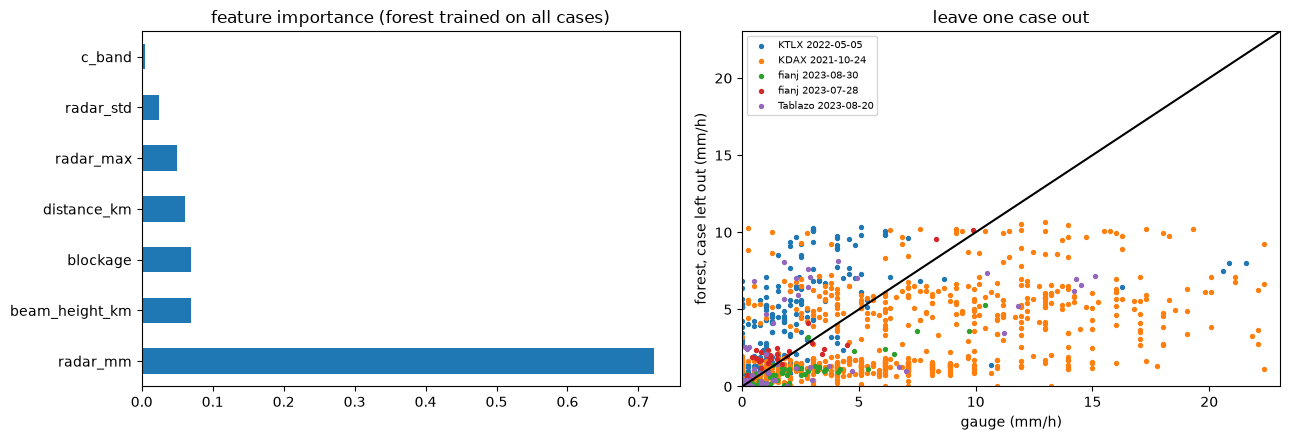

In [6]:
imp = RainForestQPE().fit(df).importance()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
imp.plot.barh(ax=axes[0])
axes[0].set(title="feature importance (forest trained on all cases)")
for case, d in out.groupby("case", sort=False):
    axes[1].scatter(d.gauge_mm, d.forest, s=8, label=case.split(" (")[0])
lim = np.percentile(out.gauge_mm, 99.5)
axes[1].plot([0, lim], [0, lim], "k")
axes[1].set(xlim=(0, lim), ylim=(0, lim), xlabel="gauge (mm/h)", ylabel="forest, case left out (mm/h)", title="leave one case out")
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/01_rainforest.png", dpi=110)
plt.show()

## Takeaways
- **Across events and radars the forest does not help.** Trained on four cases and tested on the fifth, its error is
  larger than the radar's own on four of five cases (all gauge-hours: MAE 3.05 mm against 2.66 mm for radar only).
  Even the simplest learned correction, one factor from the other cases, helps only where the held-out case happens
  to share the others' bias (fianj 30 Aug) and badly hurts KTLX, which was already right (bias 1.08 -> 2.09).
- **The reason is in the data, not the model.** The radar/gauge ratio of the five cases ranges from 0.43 to 1.08,
  driven by things the features do not see (drop sizes, rain below the beam, local gauge siting). With one event per
  radar there is nothing consistent to learn.
- **A random split looks good and is misleading.** Shuffling gauge-hours puts samples of the same event on both sides,
  so the forest learns each event's bias from its neighbours: MAE 1.71 mm. That number says nothing about a new event.
  RainForest itself was trained on years of Swiss data from the same radars and gauges it was applied to.
- **What it would take:** many events from the same radars and region (a season or more), polarimetric features
  at several heights rather than the final product, and evaluation on held-out events. For India: a monsoon of
  MOSDAC or IMD volumes with matching gauges. Until then, gauge merging (radarwow-merging) is the better use of gauges.